In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.datasets import load_diabetes

In [45]:
data=pd.read_csv("diabetes.csv")

In [61]:
X=data.drop("Outcome",axis=1)
y=data["Outcome"]

In [62]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42)


In [63]:
lin=LinearRegression().fit(X_train,y_train)


In [64]:
r=GridSearchCV(
    Ridge(),
    {"alpha":[0.001,0.01,1,10,100]},
    cv=5,
    scoring="neg_mean_squared_error"
)
r.fit(X_train,y_train)
ridge=r.best_estimator_

In [65]:
l=GridSearchCV(
    Lasso(max_iter=1000),
    {"alpha":[0.001,.01,0.1,1,10]},
    cv=5,
    scoring="neg_mean_squared_error"
)
l.fit(X_train,y_train)
lasso=l.best_estimator_

In [66]:
models={
    "Linear":lin,
    "Ridge":ridge,
    "Lasso":lasso
}
row=[]

In [67]:
for name,model in models.items():
    y_pred=model.predict(X_test)
    mse=mean_squared_error(y_pred,y_test)
    rs=r2_score(y_pred,y_test)

    row.append([
        name,
        mse,
        rs 
    ])

In [68]:
print(row)

[['Linear', 0.17104527280850101, -1.2226896983465618], ['Ridge', 0.17159157208036954, -1.2341956307709596], ['Lasso', 0.17142704792493244, -1.2328104658626358]]


In [69]:
result=pd.DataFrame(
    row,
    columns=["Name","MSE","R2_Score"]
)

In [70]:
print(result)

     Name       MSE  R2_Score
0  Linear  0.171045 -1.222690
1   Ridge  0.171592 -1.234196
2   Lasso  0.171427 -1.232810


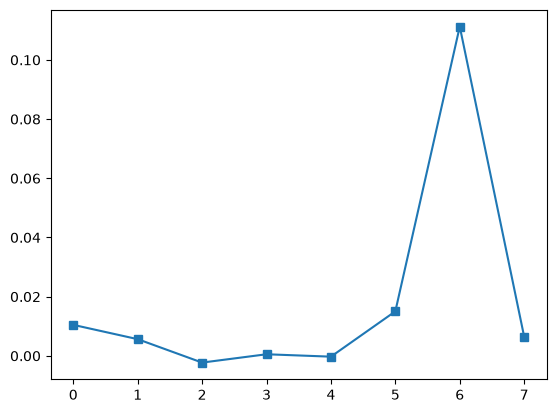

In [71]:
plt.figsize=(10,10)
plt.plot(lin.coef_,"s-",label="Linear")

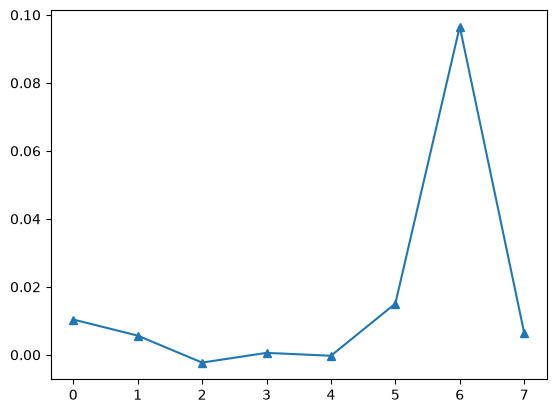

In [59]:
plt.plot(ridge.coef_,"^-",label="Ridge")

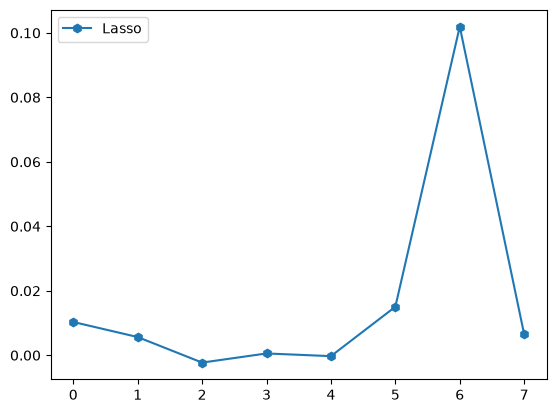

In [60]:
plt.plot(lasso.coef_,"h-",label="Lasso")
plt.legend()